In [1]:

import os, sys, math, glob, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from scipy.signal import welch, butter, filtfilt
from scipy.stats import kurtosis
import mne

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    try:
        print("GPU:", torch.cuda.get_device_name(0))
    except:
        pass


Device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


##Cell 2: Checking GPU Availability and Importing the dataset
1) Creates a Subjects Range from 1 to 66 patients  
2) sampling rate in dataset = 500 readings every second
3) 5-second windows --> cuts EEG data into 5-second pieces
4) 50% overlap --> 50% overlap between EEG segments
5) number of Channels = 19

In [2]:
##Cell 2
datasetPath = r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG"  
subjects = [f"sub-{i:03d}" for i in range(1,66)]  
fs_target = 500  # sampling rate in dataset (already 500)
seg_sec = 5      # 5-second windows
overlap = 0.5    # 50% overlap
window_samples = int(seg_sec * fs_target)
step_samples = int(window_samples * (1 - overlap))
n_channels_expected = 19
save_dir = Path("results_bilstm")
save_dir.mkdir(exist_ok=True)


In [3]:
# Cell 3: ueses wavelet-packet proxy

In [4]:
# Cell 3
use_tqwt = False
try:
    import tqwt  # preferred package if available
    use_tqwt = True
    print("tqwt package available.")
except Exception as e:
    print("tqwt not found. Will use fallback (wavelet-packet approx) if necessary.")
    use_tqwt = False

# Fallback: we'll use pywt WaveletPacket as approximate multi-band split when tqwt unavailable
try:
    import pywt
    has_pywt = True
except:
    has_pywt = False
    raise ImportError("pywt not installed. Please install pywt (pip install PyWavelets).")


tqwt not found. Will use fallback (wavelet-packet approx) if necessary.


Cell 4: 
This cell extracts useful information (features) from raw 
EEG signals so that the Bi-LSTM model can understand them better.
Entropy --> quantify the impurity, disorder, or uncertainty within a dataset.
1) shannon_entropy --> How random or unpredictable the EEG signal is
2) tsallis_entropy --> Finding rare spikes in EEG that normal measures might miss
3) renyi_entropy --> Measures how concentrated the EEG signal is
4) katz_fd --> Signal complexity,How rough or jagged the EEG signal is
5) kurtosis_feature --> Peakedness of the EEG signal

In [5]:
# Cell 4: feature functions
def shannon_entropy(x, bins=100):
    p, _ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return -np.sum(p * np.log2(p))

def tsallis_entropy(x, q=2.0, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    if q == 1.0:
        return -np.sum(p * np.log(p))
    return (1.0 - np.sum(p**q)) / (q - 1.0)

def renyi_entropy(x, q=0.5, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return (1.0/(1.0 - q)) * np.log(np.sum(p**q))

def katz_fd(x):
    x = np.asarray(x)
    n = len(x)
    if n < 2:
        return 0.0
    L = np.sum(np.sqrt(1 + np.diff(x)**2))
    d = np.max(np.sqrt((np.arange(n) - 0)**2 + (x - x[0])**2))
    if L == 0 or d == 0:
        return 0.0
    return np.log10(n) / (np.log10(n) + np.log10(d / L))

def kurtosis_feature(x):
    return float(kurtosis(x, fisher=False, nan_policy='omit'))

# wrapper to compute 4 features from a 1D subband
def features_from_subband(x):
    x = np.asarray(x)
    if x.std() == 0:
        x = x - x.mean()
    return [katz_fd(x), tsallis_entropy(x, q=2.0), renyi_entropy(x, q=0.5), kurtosis_feature(x)]


In [6]:
# Cell 5: estimate Q,R,J from signal power (simple heuristic)
def estimate_tqwt_params(signal, fs):
    # PSD to find dominant freq f0 and approximate bandwidth
    f, Pxx = welch(signal, fs=fs, nperseg=min(len(signal), 2048))## Welches Methods 
    f0 = f[np.argmax(Pxx)]                                       ##Finds frequency with maximum power(This is the strongest brain rhythm)
    # half-power bandwidth approx
    peak = np.max(Pxx)
    inds = np.where(Pxx >= peak/2)[0]
    if len(inds) > 1:
        bw = f[inds[-1]] - f[inds[0]]
    else:
        bw = max(1.0, f0*0.5)
    Q = max(0.5, float(f0) / max(bw, 1e-6))
    # redundancy heuristic: bound between 2 and 12
    R = int(np.clip(fs / (2 * max(f0,1.0)), 2, 12))
    # J selection: want ~2 Hz subband width: J ~ log2((fs/2)/target_bw)
    target_bw = 2.0
    J = int(np.clip(np.floor(np.log2((fs/2)/target_bw)), 3, 8))
    return float(Q), int(R), int(J)

# quick test (won't run until dataset provided)
# print(estimate_tqwt_params(np.random.randn(1000), fs_target))


In [7]:
# Cell 6: decomposition function returning list of subband time-series (length J+1)
def decompose_tqwt(signal, Q, R, J, fs):
    # Try tqwt library if available
    if use_tqwt:
        try:
            # tqwt API vary. Example: tqwt.tqwt(signal, Q, r, J) -> coeffs or subbands
            coeffs = tqwt.tqwt(signal, Q, R, J)  # may require adaptation
            # user must adapt if API differs. We'll expect reconstructed subbands returned.
            return coeffs
        except Exception as e:
            pass
    # Fallback: use wavelet packet decomposition to produce J+1 components
    wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='symmetric', maxlevel=J)
    # Collect nodes at level J (details approximating bands)
    nodes = [node.path for node in wp.get_level(J, order='freq')]
    subbands = []
    for path in nodes:
        node_data = wp[path].data
        # Reconstruct node to full length via inverse transform on that node only
        # Simpler: upsample node_data to original length by interpolation
        up = np.interp(np.linspace(0, len(node_data)-1, len(signal)), np.arange(len(node_data)), node_data)
        subbands.append(up)
    # ensure we return exactly J+1 bands; if fewer, pad with zeros
    if len(subbands) < J+1:
        for _ in range(J+1 - len(subbands)):
            subbands.append(np.zeros_like(signal))
    return subbands[:J+1]


In [8]:
import pandas as pd
from pathlib import Path

data_root = Path(datasetPath)
label_file = Path(r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/labels.xlsx")

# read Excel file
labels_df = pd.read_excel(label_file)

# clean column names
labels_df.columns = labels_df.columns.str.strip().str.lower()

# Normalize label text and build dictionary
labels = {}
for _, row in labels_df.iterrows():
    sid = str(row['subject']).strip()
    lab = str(row['label']).strip().lower()

    if 'a' in lab or 'alzheimer' in lab:
        labels[sid] = 1
    elif 'control' in lab or 'c' in lab or 'healthy' in lab:
        labels[sid] = 0
    elif lab in ['1', '0']:
        labels[sid] = int(lab)
    else:
        labels[sid] = None


# --- Build manifest: subject, EEG file path, label ---
manif = []

for sub in subjects:
    subdir = data_root / sub
    if not subdir.exists():
        subdir = next(data_root.glob(f"**/{sub}"), None)
        if subdir is None:
            print("Missing:", sub)
            continue

    eeg_files = list(subdir.glob("**/*.set")) + \
                list(subdir.glob("**/*.edf")) + \
                list(subdir.glob("**/*.bdf"))

    if not eeg_files:
        print("No EEG file for", sub)
        continue

    filepath = eeg_files[0]
    label = labels.get(sub, None)

    if label is None:
        print("Label missing for", sub, "- skipping.")
        continue

    manif.append((sub, str(filepath), int(label)))

print("Subjects collected:", len(manif))
print("Example:", manif[:3])



Subjects collected: 65
Example: [('sub-001', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-001/eeg/sub-001_task-eyesclosed_eeg.set', 1), ('sub-002', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-002/eeg/sub-002_task-eyesclosed_eeg.set', 1), ('sub-003', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-003/eeg/sub-003_task-eyesclosed_eeg.set', 1)]


In [9]:
# Cell 8: segmentation and live TQWT feature extraction (fixed)

def bandpass(x, lo=0.5, hi=45, fs=fs_target, order=4):
    b, a = butter(order, [lo/(fs/2), hi/(fs/2)], btype='band')
    return filtfilt(b, a, x)

all_features = []
all_labels = []
all_subject_idx = []

for subj_idx, (sub, filepath, label) in enumerate(manif):
    print(f"\nProcessing {sub} ({subj_idx+1}/{len(manif)}) label={label}")

    # --- Load EEG (.set) safely ---
    try:
        raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')
    except Exception:
        raw = mne.io.read_raw_eeglab(filepath, preload=False, verbose='ERROR')
        raw.load_data()

    raw.pick_types(eeg=True)
    data = raw.get_data()
    n_ch, n_samps = data.shape
    fs = raw.info['sfreq']

    # --- Bandpass filter (0.5–45 Hz) ---
    for ci in range(n_ch):
        data[ci] = bandpass(data[ci], 0.5, 45, fs)

    # --- Segment into 5s windows (50% overlap) ---
    total_segments = 0
    for start in range(0, int(n_samps - window_samples), step_samples):
        end = start + window_samples
        if end > n_samps:
            break
        seg = data[:, start:end]
        if seg.shape[1] < window_samples:
            continue

        total_segments += 1
        # Estimate data-driven TQWT parameters (Q, R, J)
        Q, R, J = estimate_tqwt_params(seg[0], fs)
        seg_feats = []

        # --- TQWT decomposition and feature extraction ---
        for ch in range(n_ch):
            subbands = decompose_tqwt(seg[ch], Q, R, J, fs)
            for sb in subbands:
                seg_feats.extend(features_from_subband(sb))

        expected_len = (J + 1) * 4 * n_channels_expected
        if len(seg_feats) < expected_len:
            seg_feats += [0.0] * (expected_len - len(seg_feats))

        all_features.append(seg_feats)
        all_labels.append(label)
        all_subject_idx.append(sub)

    print(f"{sub}: {total_segments} segments extracted.")

    # --- Save checkpoint every 5 subjects ---
    if (subj_idx + 1) % 5 == 0:
        np.save(save_dir / "features_checkpoint.npy", np.array(all_features, dtype=object))
        pd.DataFrame({"label": all_labels, "sub": all_subject_idx}).to_csv(
            save_dir / "labels_checkpoint.csv", index=False
        )

print("\nFeature extraction done. Total segments:", len(all_features))
X = np.array(all_features, dtype=np.float32)
y = np.array(all_labels, dtype=np.int64)
print("X shape:", X.shape, "y shape:", y.shape)



Processing sub-001 (1/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-001: 238 segments extracted.

Processing sub-002 (2/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-002: 316 segments extracted.

Processing sub-003 (3/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-003: 121 segments extracted.

Processing sub-004 (4/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-004: 281 segments extracted.

Processing sub-005 (5/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-005: 320 segments extracted.

Processing sub-006 (6/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-006: 253 segments extracted.

Processing sub-007 (7/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-007: 306 segme

In [10]:
# Cell 9: PyTorch Dataset
class EEGFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# standardize features (fit on all for now; better: fit on train in CV loop)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)
np.save(save_dir/"scaler_mean.npy", sc.mean_)
np.save(save_dir/"scaler_scale.npy", sc.scale_)

dataset = EEGFeatureDataset(X_scaled, y)


In [11]:
# Cell 10: mixup augmentation
def mixup_data(x, y, alpha=0.4):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [12]:
# Cell 11: BiLSTM classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, n_layers=2, dropout=0.4):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        # treat features as a sequence by splitting into "timesteps"
        # choose a timestep length: we can partition features into channels*subbands steps
        # We'll set timesteps = n_channels_expected and features_per_step = input_dim / timesteps
        self.timesteps = n_channels_expected
        assert input_dim % self.timesteps == 0, "input_dim must be divisible by timesteps"
        self.feat_per_step = input_dim // self.timesteps
        self.lstm = nn.LSTM(self.feat_per_step, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=False, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        # x: batch x input_dim
        b = x.size(0)
        x = x.view(b, self.timesteps, self.feat_per_step)  # batch x timesteps x feat_per_step
        out, _ = self.lstm(x)  # batch x timesteps x (2*hidden_dim)
        # use last timestep
        out = out[:, -1, :]
        out = self.fc(out).squeeze(1)
        return out  # logits


In [13]:
# Cell 12: training + 10-fold CV
from sklearn.utils.class_weight import compute_class_weight
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

INPUT_DIM = X_scaled.shape[1]
EPOCHS = 80
BATCH = 64
best_overall = {"auc":0.0, "model_path": None}

fold = 0
results = []

for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    print(f"\n===== Fold {fold} =====")
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # compute class weights for criterion
    cw = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    weight_tensor = torch.tensor([cw[0], cw[1]]).float().to(device)  # not directly used in BCEWithLogits
    # use pos_weight in BCEWithLogits for binary imbalance: pos_weight = weight of positive class
    # derive pos_weight = cw[1] / cw[0]
    pos_weight = torch.tensor([cw[1]/cw[0]]).float().to(device)

    train_ds = EEGFeatureDataset(X_train, y_train)
    test_ds = EEGFeatureDataset(X_test, y_test)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

    model = BiLSTMClassifier(INPUT_DIM, hidden_dim=256, n_layers=2, dropout=0.4).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=5, factor=0.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # handles imbalance

    best_auc = 0.0
    best_model_path = save_dir / f"best_fold{fold}.pt"
    early_stop_count = 0

    for epoch in range(1, EPOCHS+1):
        model.train()
        epoch_loss = 0.0
        all_preds = []
        all_targets = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            # mixup
            xb, ya, yb2, lam = mixup_data(xb, yb.long(), alpha=0.4)
            xb, ya, yb2 = xb.to(device).float(), ya.to(device).float(), yb2.to(device).float()
            optimizer.zero_grad()
            logits = model(xb)
            loss = mixup_criterion(criterion, logits, ya, yb2, lam)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()*xb.size(0)
            preds = torch.sigmoid(logits).detach().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_targets.extend(ya.detach().cpu().numpy().tolist())
        epoch_loss /= len(train_loader.dataset)
        # eval
        model.eval()
        y_true = []
        y_score = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                logits = model(xb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                y_score.extend(probs.tolist())
                y_true.extend(yb.numpy().tolist())
        # compute AUC
        try:
            auc = roc_auc_score(y_true, y_score)
        except:
            auc = 0.5
        print(f"Fold{fold} Epoch {epoch:02d} loss:{epoch_loss:.4f} val_auc:{auc:.4f}")
        scheduler.step(auc)

        # checkpoint
        if auc > best_auc:
            torch.save(model.state_dict(), best_model_path)
            best_auc = auc
            early_stop_count = 0
        else:
            early_stop_count += 1
        if early_stop_count >= 12:
            print("Early stopping.")
            break

    # load best model for fold and evaluate detailed metrics
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    y_true = []
    y_score = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device).float()
            logits = model(xb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            y_score.extend(probs.tolist())
            y_true.extend(yb.numpy().tolist())
    y_pred = [1 if p>=0.5 else 0 for p in y_score]
    auc = roc_auc_score(y_true, y_score)
    cm = confusion_matrix(y_true, y_pred)
    crep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results.append({"fold":fold, "auc":auc, "cm":cm, "report":crep, "model_path":str(best_model_path)})
    print("Fold", fold, "AUC", auc, "CM\n", cm)
    # track best overall
    if auc > best_overall["auc"]:
        best_overall["auc"] = auc
        best_overall["model_path"] = str(best_model_path)

# save results summary
import pickle
with open(save_dir/"cv_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("CV done. Best overall AUC:", best_overall["auc"], "model:", best_overall["model_path"])



===== Fold 1 =====
Fold1 Epoch 01 loss:0.5387 val_auc:0.8543
Fold1 Epoch 02 loss:0.4646 val_auc:0.8938
Fold1 Epoch 03 loss:0.4350 val_auc:0.9109
Fold1 Epoch 04 loss:0.4201 val_auc:0.9259
Fold1 Epoch 05 loss:0.4100 val_auc:0.9296
Fold1 Epoch 06 loss:0.4040 val_auc:0.9359
Fold1 Epoch 07 loss:0.3837 val_auc:0.9455
Fold1 Epoch 08 loss:0.3647 val_auc:0.9446
Fold1 Epoch 09 loss:0.3609 val_auc:0.9565
Fold1 Epoch 10 loss:0.3546 val_auc:0.9576
Fold1 Epoch 11 loss:0.3457 val_auc:0.9554
Fold1 Epoch 12 loss:0.3272 val_auc:0.9634
Fold1 Epoch 13 loss:0.3181 val_auc:0.9658
Fold1 Epoch 14 loss:0.3115 val_auc:0.9684
Fold1 Epoch 15 loss:0.3097 val_auc:0.9715
Fold1 Epoch 16 loss:0.2965 val_auc:0.9729
Fold1 Epoch 17 loss:0.2907 val_auc:0.9723
Fold1 Epoch 18 loss:0.2885 val_auc:0.9710
Fold1 Epoch 19 loss:0.2941 val_auc:0.9747
Fold1 Epoch 20 loss:0.2981 val_auc:0.9730
Fold1 Epoch 21 loss:0.2742 val_auc:0.9731
Fold1 Epoch 22 loss:0.2844 val_auc:0.9751
Fold1 Epoch 23 loss:0.2739 val_auc:0.9740
Fold1 Epoch 24

/tmp/ipykernel_137774/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold2 Epoch 01 loss:0.5474 val_auc:0.8339
Fold2 Epoch 02 loss:0.4750 val_auc:0.8851
Fold2 Epoch 03 loss:0.4499 val_auc:0.9080
Fold2 Epoch 04 loss:0.4285 val_auc:0.9231
Fold2 Epoch 05 loss:0.4081 val_auc:0.9409
Fold2 Epoch 06 loss:0.3988 val_auc:0.9335
Fold2 Epoch 07 loss:0.3911 val_auc:0.9582
Fold2 Epoch 08 loss:0.3731 val_auc:0.9595
Fold2 Epoch 09 loss:0.3565 val_auc:0.9577
Fold2 Epoch 10 loss:0.3609 val_auc:0.9648
Fold2 Epoch 11 loss:0.3325 val_auc:0.9656
Fold2 Epoch 12 loss:0.3206 val_auc:0.9699
Fold2 Epoch 13 loss:0.3350 val_auc:0.9739
Fold2 Epoch 14 loss:0.3156 val_auc:0.9727
Fold2 Epoch 15 loss:0.2996 val_auc:0.9780
Fold2 Epoch 16 loss:0.3086 val_auc:0.9756
Fold2 Epoch 17 loss:0.3040 val_auc:0.9762
Fold2 Epoch 18 loss:0.3062 val_auc:0.9798
Fold2 Epoch 19 loss:0.3019 val_auc:0.9784
Fold2 Epoch 20 loss:0.2935 val_auc:0.9784
Fold2 Epoch 21 loss:0.2856 val_auc:0.9783
Fold2 Epoch 22 loss:0.2746 val_auc:0.9782
Fold2 Epoch 23 loss:0.2808 val_auc:0.9783
Fold2 Epoch 24 loss:0.2729 val_auc

/tmp/ipykernel_137774/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold3 Epoch 01 loss:0.5460 val_auc:0.8051
Fold3 Epoch 02 loss:0.4778 val_auc:0.8898
Fold3 Epoch 03 loss:0.4484 val_auc:0.9147
Fold3 Epoch 04 loss:0.4223 val_auc:0.9218
Fold3 Epoch 05 loss:0.4096 val_auc:0.9360
Fold3 Epoch 06 loss:0.4015 val_auc:0.9421
Fold3 Epoch 07 loss:0.3819 val_auc:0.9475
Fold3 Epoch 08 loss:0.3670 val_auc:0.9538
Fold3 Epoch 09 loss:0.3603 val_auc:0.9524
Fold3 Epoch 10 loss:0.3416 val_auc:0.9633
Fold3 Epoch 11 loss:0.3427 val_auc:0.9654
Fold3 Epoch 12 loss:0.3277 val_auc:0.9679
Fold3 Epoch 13 loss:0.3233 val_auc:0.9662
Fold3 Epoch 14 loss:0.3204 val_auc:0.9733
Fold3 Epoch 15 loss:0.3050 val_auc:0.9705
Fold3 Epoch 16 loss:0.3103 val_auc:0.9739
Fold3 Epoch 17 loss:0.3058 val_auc:0.9741
Fold3 Epoch 18 loss:0.3009 val_auc:0.9737
Fold3 Epoch 19 loss:0.2985 val_auc:0.9742
Fold3 Epoch 20 loss:0.2897 val_auc:0.9755
Fold3 Epoch 21 loss:0.2651 val_auc:0.9733
Fold3 Epoch 22 loss:0.2745 val_auc:0.9783
Fold3 Epoch 23 loss:0.2793 val_auc:0.9752
Fold3 Epoch 24 loss:0.2707 val_auc

...

/tmp/ipykernel_137774/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold9 Epoch 01 loss:0.5515 val_auc:0.8480
Fold9 Epoch 02 loss:0.4762 val_auc:0.9069
Fold9 Epoch 03 loss:0.4435 val_auc:0.9233
Fold9 Epoch 04 loss:0.4246 val_auc:0.9343
Fold9 Epoch 05 loss:0.4121 val_auc:0.9406
Fold9 Epoch 06 loss:0.3975 val_auc:0.9453
Fold9 Epoch 07 loss:0.3946 val_auc:0.9531
Fold9 Epoch 08 loss:0.3731 val_auc:0.9592
Fold9 Epoch 09 loss:0.3675 val_auc:0.9606
Fold9 Epoch 10 loss:0.3450 val_auc:0.9643
Fold9 Epoch 11 loss:0.3479 val_auc:0.9697
Fold9 Epoch 12 loss:0.3396 val_auc:0.9669
Fold9 Epoch 13 loss:0.3327 val_auc:0.9735
Fold9 Epoch 14 loss:0.3212 val_auc:0.9729
Fold9 Epoch 15 loss:0.3113 val_auc:0.9751
Fold9 Epoch 16 loss:0.3065 val_auc:0.9748
Fold9 Epoch 17 loss:0.3090 val_auc:0.9767
Fold9 Epoch 18 loss:0.2998 val_auc:0.9754
Fold9 Epoch 19 loss:0.2922 val_auc:0.9759
Fold9 Epoch 20 loss:0.2960 val_auc:0.9764
Fold9 Epoch 21 loss:0.2775 val_auc:0.9747
Fold9 Epoch 22 loss:0.2807 val_auc:0.9767
Fold9 Epoch 23 loss:0.2802 val_auc:0.9753
Fold9 Epoch 24 loss:0.2706 val_auc

/tmp/ipykernel_137774/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold10 Epoch 01 loss:0.5440 val_auc:0.8232
Fold10 Epoch 02 loss:0.4797 val_auc:0.8996
Fold10 Epoch 03 loss:0.4472 val_auc:0.9232
Fold10 Epoch 04 loss:0.4195 val_auc:0.9238
Fold10 Epoch 05 loss:0.4166 val_auc:0.9291
Fold10 Epoch 06 loss:0.4043 val_auc:0.9308
Fold10 Epoch 07 loss:0.3884 val_auc:0.9422
Fold10 Epoch 08 loss:0.3782 val_auc:0.9540
Fold10 Epoch 09 loss:0.3604 val_auc:0.9609
Fold10 Epoch 10 loss:0.3446 val_auc:0.9635
Fold10 Epoch 11 loss:0.3376 val_auc:0.9657
Fold10 Epoch 12 loss:0.3322 val_auc:0.9640
Fold10 Epoch 13 loss:0.3260 val_auc:0.9736
Fold10 Epoch 14 loss:0.3189 val_auc:0.9738
Fold10 Epoch 15 loss:0.3197 val_auc:0.9746
Fold10 Epoch 16 loss:0.3083 val_auc:0.9723
Fold10 Epoch 17 loss:0.2960 val_auc:0.9771
Fold10 Epoch 18 loss:0.2995 val_auc:0.9764
Fold10 Epoch 19 loss:0.3031 val_auc:0.9776
Fold10 Epoch 20 loss:0.2889 val_auc:0.9754
Fold10 Epoch 21 loss:0.2990 val_auc:0.9797
Fold10 Epoch 22 loss:0.2775 val_auc:0.9787
Fold10 Epoch 23 loss:0.2768 val_auc:0.9791
Fold10 Epoc

/tmp/ipykernel_137774/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


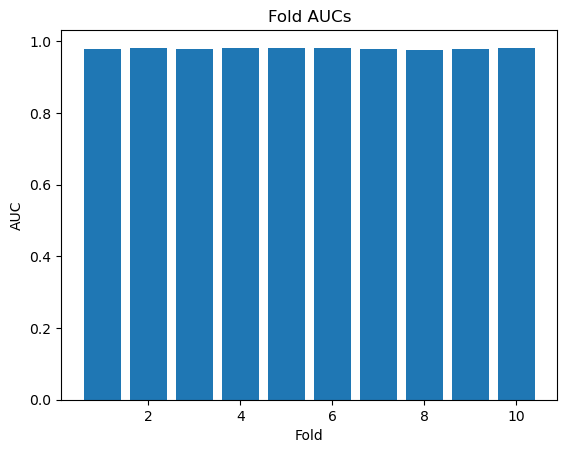

Best fold: 6 AUC: 0.9820587025967042
Classification report (best fold):
              precision    recall  f1-score      support
0              0.925773  0.923868  0.924820   972.000000
1              0.936914  0.938514  0.937713  1171.000000
accuracy       0.931871  0.931871  0.931871     0.931871
macro avg      0.931344  0.931191  0.931267  2143.000000
weighted avg   0.931861  0.931871  0.931865  2143.000000


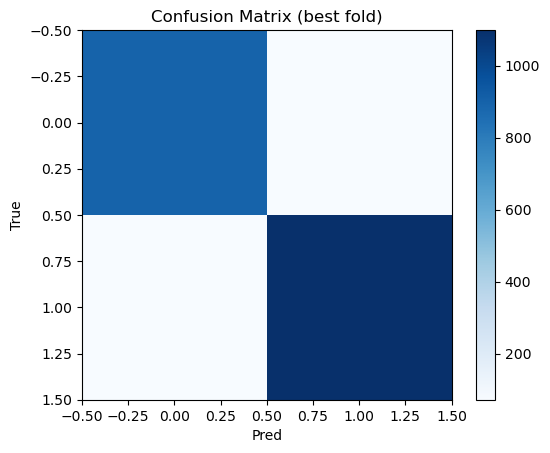

In [14]:
# Cell 13: simple plotting of fold metrics
import matplotlib.pyplot as plt
with open(save_dir/"cv_results.pkl","rb") as f:
    res = pickle.load(f)

# aggregate AUCs
aucs = [r['auc'] for r in res]
plt.figure()
plt.bar(range(1,len(aucs)+1), aucs)
plt.xlabel("Fold"); plt.ylabel("AUC"); plt.title("Fold AUCs")
plt.savefig(save_dir/"fold_aucs.png", dpi=150)
plt.show()

# show confusion matrix of best fold
best = max(res, key=lambda x: x['auc'])
print("Best fold:", best['fold'], "AUC:", best['auc'])
print("Classification report (best fold):")
print(pd.DataFrame(best['report']).T)
cm = best['cm']
plt.figure()
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion Matrix (best fold)")
plt.savefig(save_dir/"best_confusion.png", dpi=150)
plt.show()


In [15]:
# Cell 14: final save and example report
print("Best model saved at:", best_overall["model_path"])
# load and show sample predictions with that model (if desired)
final_model = BiLSTMClassifier(INPUT_DIM).to(device)
final_model.load_state_dict(torch.load(best_overall["model_path"]))
final_model.eval()
# Optionally export to ONNX if requested (skipped per choice)


Best model saved at: results_bilstm/best_fold6.pt


/tmp/ipykernel_137774/2083957647.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  final_model.load_state_dict(torch.load(best_overall["model_path"]))


BiLSTMClassifier(
  (lstm): LSTM(28, 256, num_layers=2, batch_first=True, dropout=0.4)
  (fc): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Best fold: 6 | AUC: 0.982


/tmp/ipykernel_137774/3696722634.py:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


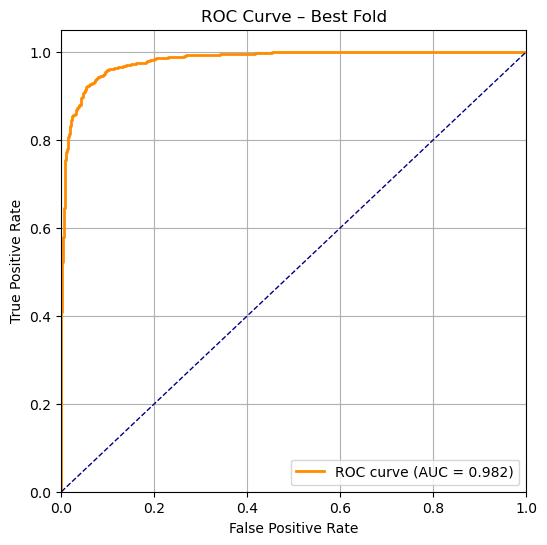

In [16]:
# Cell A: Plot ROC curve for best fold
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Load results
with open(save_dir / "cv_results.pkl", "rb") as f:
    res = pickle.load(f)

best = max(res, key=lambda x: x['auc'])
y_true = []
y_score = []

# Reload test predictions for best fold
best_fold = best['fold']
print(f"Best fold: {best_fold} | AUC: {best['auc']:.3f}")

# Extract test data from saved fold (re-run same split for ROC)
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold = 0
for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    if fold == best_fold:
        X_test = X_scaled[test_idx]
        y_test = y[test_idx]
        break

# Reload best model
best_model_path = best['model_path']
model = BiLSTMClassifier(X_scaled.shape[1]).to(device)
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_test).to(device).float()
    preds = torch.sigmoid(model(xb)).cpu().numpy().flatten()

fpr, tpr, thresholds = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Best Fold')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig(save_dir / "roc_curve_best_fold.png", dpi=150)
plt.show()
